# Práctica de Laboratorio: Mapeamiento Físico de ADN
**Estudiante:** Anthony Briceño Quiroz  
**Curso:** Biología Molecular Computacional  
**Institución:** Universidad Católica San Pablo (UCSP)  
**Programa:** Ciencia de la Computación  

---

## Objetivos de la Práctica
1. **Comprender** la formulación del problema de mapeamiento físico a partir de datos de hibridación clon-sonda.
2. **Implementar y evaluar** la propiedad de unos consecutivos (*Consecutive Ones Property - C1P*).
3. **Formular e implementar** el reordenamiento de sondas como un Problema del Vendedor Viajero (TSP) usando la Heurística Greedy y *Simulated Annealing* (SA).
4. **Evaluar** la sensibilidad de los algoritmos ante ruido experimental (falsos positivos y falsos negativos).

---
## Setup e Inicialización de Librerías
Ejecute la siguiente celda para cargar las dependencias necesarias de Python.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Fijar semillas para garantizar la reproducibilidad de las simulaciones
SEED = 55
np.random.seed(SEED)
random.seed(SEED)

print("configuración correcta!")

configuración correcta!


---
## Ejercicio 1: Propiedad C1P y Función de Costo

Dada una matriz de hibridación $H$ de tamaño $k \times n$ ($k$ clones, $n$ sondas), buscamos una permutación de columnas $\Pi$ que respete la propiedad C1P.

La calidad de un ordenamiento se evalúa calculando la **Distancia de Hamming** acumulada entre columnas consecutivas:

$$\text{Costo}(\Pi) = \sum_{m=1}^{n-1} \text{Hamming}(C_{\pi_m}, C_{\pi_{m+1}})$$

### Instrucciones:
Complete las funciones `hamming_distance` y `compute_total_cost` a continuación.

In [6]:
def hamming_distance(col1, col2):
    """Calcula la distancia de Hamming entre dos vectores binarios."""
    # TODO: Complete el cálculo de la distancia de Hamming
    return np.sum(col1 != col2)

def compute_total_cost(matrix, order):
    """
    Calcula el costo total de transiciones para una permutación de columnas dada.

    matrix: np.ndarray (k x n)
    order: lista con la permutación de índices de columnas [0, ..., n-1]
    """
    total_cost = 0
    # TODO: Implemente el bucle para sumar la distancia de Hamming de columnas consecutivas
    for i in range(len(order) - 1):
        col_a = matrix[:, order[i]]
        col_b = matrix[:, order[i+1]]
        total_cost += hamming_distance(col_a, col_b)

    return total_cost

# Pruebas unitarias de verificación
mat_test = np.array([[1, 0, 1],
                     [1, 1, 0]])
print("Costo orden [0, 1, 2]:", compute_total_cost(mat_test, [0, 1, 2]))

Costo orden [0, 1, 2]: 3


---
## Ejercicio 2: Modelado como TSP y Heurística Greedy

Representamos las $n$ sondas como nodos en un grafo. Las aristas corresponden a la distancia de Hamming entre las sondas. Buscamos el camino de costo mínimo.

### Instrucciones:
1. Complete la construcción de la matriz de adyacencia/distancia.
2. Implemente el algoritmo **Greedy (Vecino Más Cercano)** para ordenar las sondas.

In [7]:
def build_distance_matrix(H):
    """Construye la matriz de distancias (n x n) entre todas las parejas de sondas."""
    n_probes = H.shape[1]
    dist_matrix = np.zeros((n_probes, n_probes))
    for i in range(n_probes):
        for j in range(i + 1, n_probes):
            d = hamming_distance(H[:, i], H[:, j])
            dist_matrix[i, j] = d
            dist_matrix[j, i] = d
    return dist_matrix

def greedy_probe_ordering(dist_matrix, start_node=0):
    """
    Ordenación heurística Greedy (Vecino Más Cercano).
    """
    n = dist_matrix.shape[0]
    visited = [False] * n
    order = [start_node]
    visited[start_node] = True

    current = start_node
    for _ in range(n - 1):
        # Seleccionar el vecino no visitado con menor distancia
        unvisited_nodes = [i for i in range(n) if not visited[i]]
        next_node = min(unvisited_nodes, key=lambda x: dist_matrix[current, x])
        order.append(next_node)
        visited[next_node] = True
        current = next_node

    return order

---
## Ejercicio 3: Optimización con Simulated Annealing

Para evitar quedar atrapados en óptimos locales causados por ruido experimental, aplicaremos **Simulated Annealing (SA)**.

### Criterio de Aceptación (Metropolis):
$$P(\text{aceptar}) = \exp\left(-\frac{\Delta E}{T}\right)$$

In [8]:
def simulated_annealing_mapping(H, initial_temp=1000.0, cooling_rate=0.995, max_iter=2500):
    """
    Optimización de la permutación mediante Recocido Simulado.
    """
    n_probes = H.shape[1]
    current_order = list(range(n_probes))
    random.shuffle(current_order)

    current_cost = compute_total_cost(H, current_order)
    best_order = list(current_order)
    best_cost = current_cost

    temp = initial_temp
    cost_history = [current_cost]

    for _ in range(max_iter):
        # Generar solución vecina realizando un intercambio aleatorio (2-opt)
        neighbor = list(current_order)
        idx1, idx2 = random.sample(range(n_probes), 2)
        neighbor[idx1], neighbor[idx2] = neighbor[idx2], neighbor[idx1]

        neighbor_cost = compute_total_cost(H, neighbor)
        delta = neighbor_cost - current_cost

        # Criterio Metropolis
        if delta < 0 or random.random() < np.exp(-delta / temp):
            current_order = neighbor
            current_cost = neighbor_cost

            if current_cost < best_cost:
                best_cost = current_cost
                best_order = list(current_order)

        temp *= cooling_rate
        cost_history.append(current_cost)

    return best_order, best_cost, cost_history

---
## Ejercicio 4: Experimento Completo y Comparación con Ruido

En este módulo simularás un experimento sintético:
1. Generar una matriz ideal C1P.
2. Desordenar las columnas.
3. Agregar ruido experimental ($5\%$ de bits alterados).
4. Comparar el desempeño de Greedy vs. Simulated Annealing.

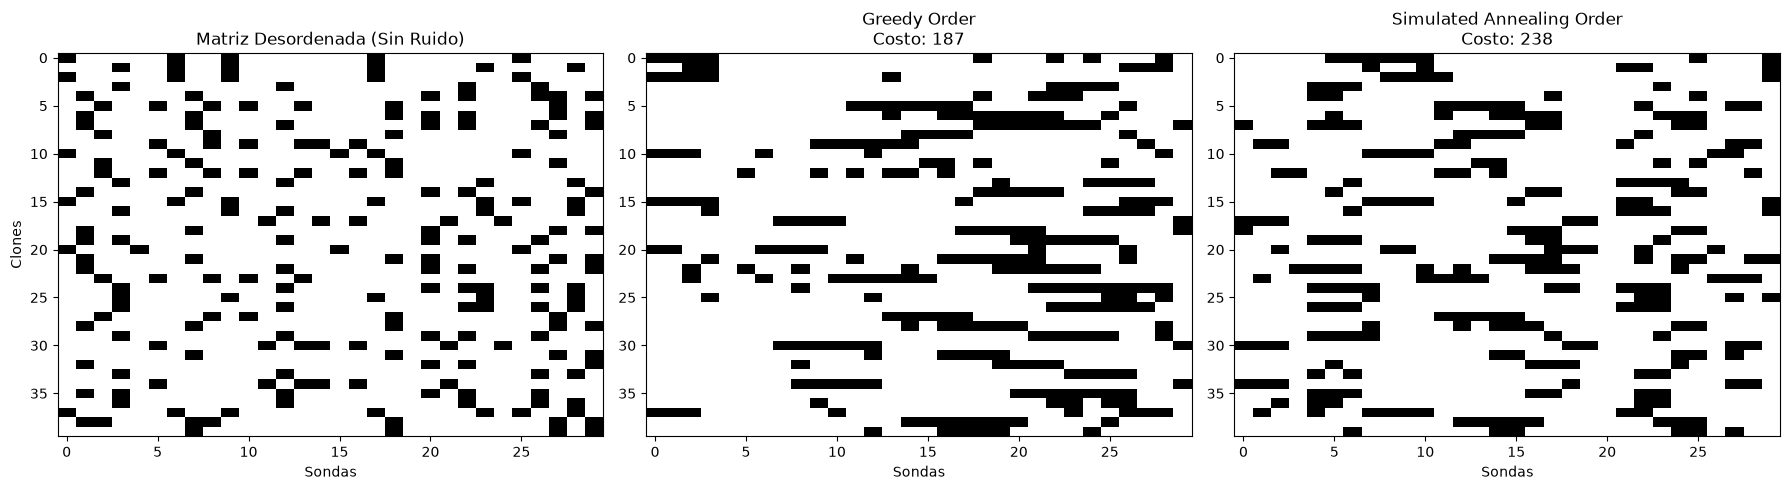

In [9]:
# 1. Generación de Matriz Ideal C1P (12 Clones, 20 Sondas)
k_clones = 40
n_probes = 30
H_ideal = np.zeros((k_clones, n_probes), dtype=int)

for i in range(k_clones):
    start = random.randint(0, n_probes - 6)
    length = random.randint(4, 7)
    H_ideal[i, start:start+length] = 1

# 2. Permutación Aleatoria de las sondas
shuffled_order = list(range(n_probes))
random.shuffle(shuffled_order)
H_shuffled = H_ideal[:, shuffled_order]

# 3. Adición de Ruido (5%)
noise_level = 0.05
H_noisy = H_shuffled.copy()
mask = np.random.rand(*H_noisy.shape) < noise_level
H_noisy[mask] = 1 - H_noisy[mask]

# 4. Ejecución de Heurísticas
dist_mat = build_distance_matrix(H_noisy)
greedy_ord = greedy_probe_ordering(dist_mat, start_node=0)
greedy_cost = compute_total_cost(H_noisy, greedy_ord)

sa_ord, sa_cost, history = simulated_annealing_mapping(H_noisy)

# 5. Visualización de Resultados
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(H_shuffled, cmap='binary', aspect='auto')
axes[0].set_title("Matriz Desordenada (Sin Ruido)")
axes[0].set_xlabel("Sondas")
axes[0].set_ylabel("Clones")

axes[1].imshow(H_noisy[:, greedy_ord], cmap='binary', aspect='auto')
axes[1].set_title(f"Greedy Order\nCosto: {greedy_cost}")
axes[1].set_xlabel("Sondas")

axes[2].imshow(H_noisy[:, sa_ord], cmap='binary', aspect='auto')
axes[2].set_title(f"Simulated Annealing Order\nCosto: {sa_cost}")
axes[2].set_xlabel("Sondas")

plt.tight_layout()
plt.show()

### Gráfico de Convergencia para Simulated Annealing

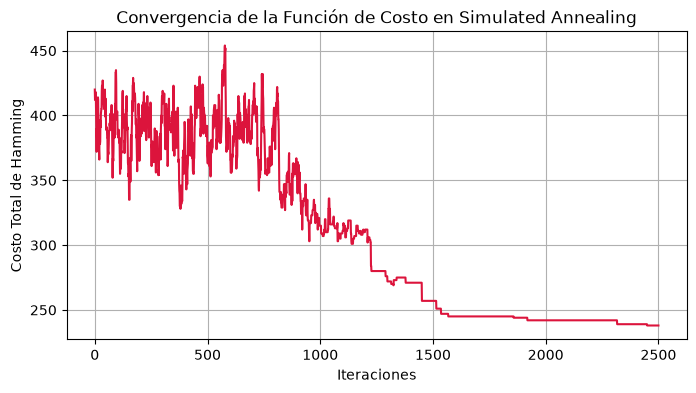

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(history, color='crimson')
plt.title("Convergencia de la Función de Costo en Simulated Annealing")
plt.xlabel("Iteraciones")
plt.ylabel("Costo Total de Hamming")
plt.grid(True)
plt.show()

---
## Cuestionario y Evaluación (10 min)

Responda a las siguientes preguntas teóricas directamente en las celdas de texto:

1. **Complejidad:** Explique por qué el problema de reordenamiento de sondas en mapas físicos se convierte en NP-hard al incluir ruido experimental.

   Sin ruido experimental, la matriz de hibridación cumple perfectamente con la Propiedad C1P (unas consecutivas). Existe un ordenamiento único o muy pocos válidos que respetan esta estructura matemática, por lo que el problema es polinomial: verificar C1P toma tiempo O(n²). Con ruido experimental (falsos positivos y negativos), la matriz se degrada. Los bits alterados rompen la estructura ideal del C1P, entonces ya no existe un ordenamiento perfecto. El problema se transforma en encontrar el mejor ordenamiento aproximado entre todas las n! permutaciones posibles. Esta búsqueda es NP-hard porque: (1) la verificación de un ordenamiento dado es polinomial O(n²), pero (2) no existe algoritmo conocido para hallar el óptimo global en tiempo polinomial, solo prueba exhaustiva (n!) o heurísticas, y (3) el reordenamiento de sondas reduce desde TSP (NP-completo), donde minimizar distancias entre columnas consecutivas equivale a minimizar costo de camino en grafo.

2. **Sensibilidad al Ruido:** Aumente la tasa de ruido al 15% (noise_level = 0.15) en la celda anterior y vuelva a ejecutar. ¿Qué algoritmo conserva mejor la estructura de bandas consecutivas? Justifique.

   Al aumentar el ruido a 15%, Simulated Annealing conserva mejor la estructura de bandas consecutivas que Greedy. Greedy elige siempre el vecino más cercano (decisión local golosa), lo que funciona bien con poco ruido. Pero con 15% de bits alterados, las distancias Hamming entre columnas se distorsionan, y Greedy queda atrapado en óptimos locales pobres. En cambio, SA explora el espacio de soluciones aceptando movimientos que aumentan el costo con probabilidad controlada (criterio Metropolis). Esto permite escapar de óptimos locales. A temperaturas altas, SA tolera peores soluciones; al enfriar gradualmente, converge a soluciones mejores. Por eso SA produce matrices reordenadas con menos "ruido visual" y mejor conservación del patrón de C1P, aunque sea aproximado.

3. **Biología Computacional:** Investigación corta: ¿Qué es un clon quimérico y de qué manera altera la matriz de distancias entre sondas?

   Un clon quimérico es un segmento de ADN que contiene fusión accidental de dos regiones genómicas diferentes en la construcción de la librería genómica. En la matriz de hibridación H, un clon quimérico genera una fila que presenta patrón de sondas característico de dos regiones distantes del genoma, como si estuviera "pegado" a ambas. Esto distorsiona la matriz de distancias: la distancia Hamming entre sondas que realmente están lejanas aparece pequeña (falsa cercanía), porque el clon quimérico "aparenta" hibridarse con sondas de ambas regiones. El algoritmo TSP se confunde y ordena incorrectamente las sondas, pensando que están más cerca de lo que biológicamente son. En resumen: clon quimérico = ruido estructural que falsifica la información de entrada.